<a href="https://colab.research.google.com/github/manhakalytep/python_project/blob/main/project_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"

df = pd.read_csv(url)

df["date"] = pd.to_datetime(df["date"])

print(df.head())

       country       date  total_cases  new_cases  new_cases_smoothed  \
0  Afghanistan 2020-01-01          NaN        NaN                 NaN   
1  Afghanistan 2020-01-02          NaN        NaN                 NaN   
2  Afghanistan 2020-01-03          NaN        NaN                 NaN   
3  Afghanistan 2020-01-04          0.0        0.0                 NaN   
4  Afghanistan 2020-01-05          0.0        0.0                 NaN   

   total_cases_per_million  new_cases_per_million  \
0                      NaN                    NaN   
1                      NaN                    NaN   
2                      NaN                    NaN   
3                      0.0                    0.0   
4                      0.0                    0.0   

   new_cases_smoothed_per_million  total_deaths  new_deaths  ...  population  \
0                             NaN           NaN         NaN  ...  40578847.0   
1                             NaN           NaN         NaN  ...  40578847.0   
2 

In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nDescriptive statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (629868, 61)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629868 entries, 0 to 629867
Data columns (total 61 columns):
 #   Column                                      Non-Null Count   Dtype         
---  ------                                      --------------   -----         
 0   country                                     629868 non-null  object        
 1   date                                        629868 non-null  datetime64[ns]
 2   total_cases                                 617520 non-null  float64       
 3   new_cases                                   612628 non-null  float64       
 4   new_cases_smoothed                          611419 non-null  float64       
 5   total_cases_per_million                     617520 non-null  float64       
 6   new_cases_per_million                       612628 non-null  float64       
 7   new_cases_smoothed_per_million              611419 non-null  float64       
 8   total_deaths             

In [ ]:
df = df.drop_duplicates()

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
india = df[df["country"] == "India"].copy()

india = india.sort_values("date")

latest_india = india.iloc[-1]

print("Latest India record:")
print(latest_india[["date", "total_cases", "total_deaths"]])

Latest India record:
date            2026-10-18 00:00:00
total_cases              45056221.0
total_deaths               533849.0
Name: 255093, dtype: object


In [ ]:
countries = [
    "India",
    "United States",
    "Brazil",
    "United Kingdom",
    "Germany"
]

# Correcting 'location' to 'country'
latest = (
    df.sort_values("date")
      .groupby("country")
      .tail(1)
)

comparison = latest[
    latest["country"].isin(countries)
].copy()

print(
    comparison[
        ["country", "total_cases", "total_deaths"]
    ].sort_values("total_cases", ascending=False)
)

               country  total_cases  total_deaths
588620   United States  103436829.0     1240149.0
255093           India   45056221.0      533849.0
208745         Germany   38437953.0      174979.0
79431           Brazil   38058695.0      704109.0
586137  United Kingdom   25143403.0      232612.0


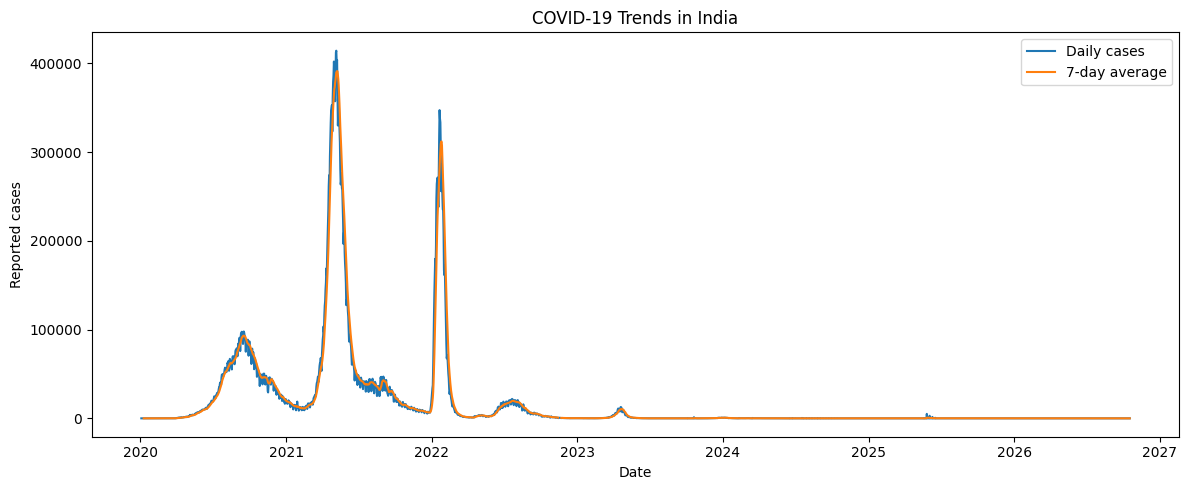

In [ ]:
india["7_day_average"] = (india["new_cases"].rolling(7).mean())

plt.figure(figsize=(12, 5))

plt.plot(india["date"], india["new_cases"],
         label="Daily cases")

plt.plot(india["date"], india["7_day_average"],
         label="7-day average")

plt.title("COVID-19 Trends in India")
plt.xlabel("Date")
plt.ylabel("Reported cases")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
countries = [
    "India",
    "United States",
    "Brazil",
    "United Kingdom",
    "Germany"
]

latest = (
    df.sort_values("date")
      .groupby("country")
      .tail(1)
)

comparison = latest[
    latest["country"].isin(countries)
].copy()

print(
    comparison[
        ["country", "total_cases", "total_deaths"]
    ].sort_values("total_cases", ascending=False)
)

               country  total_cases  total_deaths
588620   United States  103436829.0     1240149.0
255093           India   45056221.0      533849.0
208745         Germany   38437953.0      174979.0
79431           Brazil   38058695.0      704109.0
586137  United Kingdom   25143403.0      232612.0


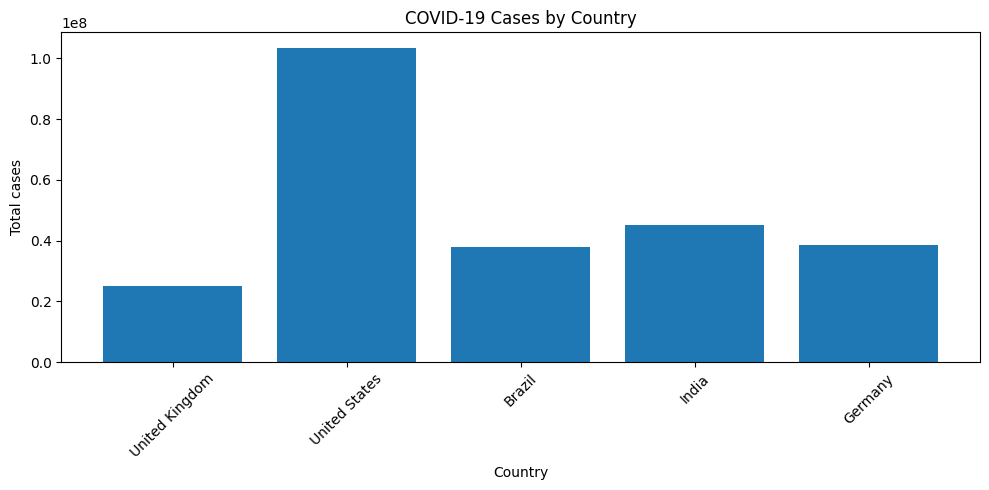

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["country"],
    comparison["total_cases"]
)

plt.title("COVID-19 Cases by Country")
plt.xlabel("Country")
plt.ylabel("Total cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()